# van der Laan et al. (2021): parametric feedback cooling and reheating of a levitated librator

F. van der Laan, F. Tebbenjohanns, R. Reimann, J. Vijayan, L. Novotny and M. Frimmer, *Sub-Kelvin
Feedback Cooling and Heating Dynamics of an Optically Levitated Librator*, Phys. Rev. Lett. **127**,
123605 (2021), [doi:10.1103/PhysRevLett.127.123605](https://doi.org/10.1103/PhysRevLett.127.123605)
(open version: arXiv:2012.14231v2, titled *Observation of radiation torque shot noise on an
optically levitated nanodumbbell*; the numbers below are from that version).

A silica nanodumbbell aligned with a linearly polarised 1565 nm tweezer librates at
$\Omega_l/2\pi$ = 757 kHz. Parametric feedback on the laser power cools the libration to
**E = 0.24(3) K**; released from feedback in high vacuum, it reheats at a rate that stops falling with
pressure below 10⁻⁷ mbar, **Γ_res = 0.50(6) K/s**, which the paper attributes to radiation torque shot
noise, predicted at **Γ_sn = 0.31 K/s** by its Eq. (3), $\Gamma_\mathrm{sn} = \tfrac12(\Delta\alpha/\alpha_x)^2\hbar P/(I\omega)$.

levisim's recoil torque noise (`Tweezer.recoil_torque_noise`, $S_\tau = \hbar k^3/(12\pi\varepsilon_0)\,\mathrm{Re}(MM^\dagger)$)
heats a libration at $S_\tau/2I$ (energy per time). This notebook

1. shows that levisim's rate equals the paper's Eq. (3) identically, and evaluates it with the paper's
   parameters (**0.31 K/s expected**) and with levisim's own dumbbell model;
2. compares levisim's libration frequency of a 2 × 136 nm dumbbell at 1050 mW with the measured 757 kHz;
3. measures the reheating rate in the time domain (`RigidBodySimulation(recoil=True)`, an ensemble
   of runs at 1.1 × 10⁻⁸ mbar) against $S_\tau/2I$ plus gas heating;
4. cools the libration with parametric feedback in the time domain
   (`RigidBodySimulation(parametric_feedback=...)`), from room temperature to the 0.24 K of the paper.

**Comparisons stated before running:** Γ_sn = 0.31 K/s (paper's Eq. (3) with its parameters; levisim
must give the same number), the measured Γ_res = 0.50(6) K/s, Ω_l/2π = 757 kHz and E = 0.24(3) K.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| particle | dumbbell of two touching silica spheres, diameter 136 nm (nominal), fused silica at 1565 nm | text |
| tweezer | 1565 nm, focal power 1050(50) mW, 0.7 NA, linear polarisation | text, Fig. 1 |
| waist | $w_0 = \lambda/(\pi\,\mathrm{NA})$ = 712 nm (paraxial diffraction limit; not stated) | assumption |
| paper's model parameters | scattered power 80 μW, Δα/α_x = 0.14, I = 1.6 × 10⁻³² kg m² | ref. [39] of the paper |
| pressure | 1.1(1) × 10⁻⁸ mbar (reheating), 300 K | text |

Axes: the paper's polarisation is its $x$ axis and $\theta$ the angle of the dumbbell in the focal
plane, i.e. the rotation about the beam axis. In levisim the polarisation is $y$, so $\theta$ is the
libration `'γ'`, measured as the tilt of the dumbbell's axis towards $x$.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from levisim.core.constants import c, kB, ħ, ε0, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, mbar, mW, nm
from levisim.physics import Dumbbell, Gas, Trap, Tweezer
from levisim.physics.materials import FUSED_SILICA
from levisim.physics.particle import body_axis_to_quaternion, quaternion_to_rotation_matrix
from levisim.physics.rotation import quaternion_from_rotation_vector, quaternion_multiply, recoil_torque_noise
from levisim.simulation import RigidBodySimulation

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()

λ, NA, P = 1565*nm, 0.7, 1050*mW
w0 = λ / (π * NA)
ω_light = 2 * π * c / λ
tweezer = Tweezer(λ=λ, wx0=w0, wy0=w0, Power=P)
dumbbell = Dumbbell(68*nm, material=FUSED_SILICA, λ=λ, orientation=body_axis_to_quaternion((0, 1, 0)))

## 1. Radiation torque shot noise: levisim against Eq. (3)

For a dipole $\alpha = \mathrm{diag}(\alpha_\perp, \alpha_\perp, \alpha_x)$ in a field along its long
axis, levisim's $S_\tau/2I$ about a perpendicular axis is
$\hbar k^3E_0^2\Delta\alpha^2/(24\pi\varepsilon_0 I)$; with the scattered power
$P = ck^4\alpha_x^2E_0^2/(12\pi\varepsilon_0)$ this is $\tfrac12(\Delta\alpha/\alpha_x)^2\hbar P/(I\omega)$, the
paper's Eq. (3). Numerically, with the paper's parameters:

In [2]:
P_sc_paper, ratio_paper, I_paper = 80e-6, 0.14, 1.6e-32
Γ_eq3 = 0.5 * ratio_paper**2 * ħ * P_sc_paper / (I_paper * ω_light) / kB
# the same through levisim's recoil_torque_noise: a field E0 along the long axis (y) that makes the
# dipole α_x scatter 80 μW
α_x = 1e-32
E0 = np.sqrt(P_sc_paper * 12 * π * ε0 / (c * tweezer.k**4 * α_x**2))
α = np.diag([α_x * (1 - ratio_paper), α_x, α_x * (1 - ratio_paper)])   # long axis along y
S = recoil_torque_noise(α, np.array([0, E0, 0]), tweezer.k)
Γ_levisim_paper = S[2, 2] / (2 * I_paper) / kB
print(f'Eq. (3) with the paper parameters: Γ_sn = {Γ_eq3:.4f} K/s (paper 0.31 K/s)')
print(f'levisim recoil_torque_noise, same parameters: S/2I = {Γ_levisim_paper:.4f} K/s '
      f'(relative difference {Γ_levisim_paper / Γ_eq3 - 1:+.1e})')

Eq. (3) with the paper parameters: Γ_sn = 0.3110 K/s (paper 0.31 K/s)
levisim recoil_torque_noise, same parameters: S/2I = 0.3110 K/s (relative difference +1.3e-15)


## 2. levisim's own dumbbell

levisim's `Dumbbell` (two coupled point dipoles, touching 136 nm spheres) in the paper's tweezer:

In [3]:
trap = Trap(tweezer=tweezer, particle=dumbbell, gas=Gas(P=1.1e-8*mbar))
α_body = np.real(np.diag(dumbbell.body_effective_polarisability_tensor(tweezer.k)))
ratio = (α_body[2] - α_body[0]) / α_body[2]
I_γ = trap.Ij['γ']
P_scattered = c * tweezer.k**4 * α_body[2]**2 * tweezer.E0**2 / (12 * π * ε0)
Γ_sn = trap.torque_noise_psd[2, 2] / (2 * I_γ) / kB
Γ_gas = trap.Γrot_j['γ'] * trap.gas.T   # γ E∞ with E∞ = T (in kelvin)
print(f'levisim dumbbell: I⊥ = {I_γ:.3e} kg m² (paper 1.6e-32), Δα/α = {ratio:.3f} (paper 0.14), '
      f'scattered power {P_scattered * 1e6:.0f} μW (paper 80 μW)')
print(f'libration frequency Ωγ/2π = {trap.Ωθ["γ"] / kHz:.1f} kHz (measured 757 kHz); COM Ωx/2π = {trap.Ωj["x"] / kHz:.0f} kHz')
print(f'recoil heating of the γ libration: {Γ_sn:.4f} K/s; gas heating at 1.1e-8 mbar: {Γ_gas:.4f} K/s; '
      f'total {Γ_sn + Γ_gas:.4f} K/s (measured Γ_res = 0.50(6) K/s)')
print(f'with the paper\'s Δα/α and I: {Γ_sn * (ratio_paper / ratio)**2 * I_γ / I_paper:.3f} K/s at levisim\'s scattered power')

levisim dumbbell: I⊥ = 3.753e-32 kg m² (paper 1.6e-32), Δα/α = 0.096 (paper 0.14), scattered power 92 μW (paper 80 μW)
libration frequency Ωγ/2π = 802.3 kHz (measured 757 kHz); COM Ωx/2π = 413 kHz
recoil heating of the γ libration: 0.0722 K/s; gas heating at 1.1e-8 mbar: 0.0162 K/s; total 0.0884 K/s (measured Γ_res = 0.50(6) K/s)
with the paper's Δα/α and I: 0.357 K/s at levisim's scattered power


levisim's coupled-dipole dumbbell is less anisotropic (Δα/α = 0.096, against 0.14 from the
literature the paper uses; the shapes notebook notes that the point-dipole model underestimates the
anisotropy of touching spheres) and heavier in rotation than the measured I = 1.6 × 10⁻³² kg m²
(the 136 nm nominal size gives 3.75 × 10⁻³²), so its shot-noise heating, 0.07 K/s, is a quarter of
the paper's 0.31 K/s. Both effects are particle-model inputs, not the noise formula, which agrees
exactly. The libration frequency of the nominal dumbbell, 802 kHz, is 6 % above the measured 757 kHz.

## 3. Reheating in the time domain

An ensemble of `RigidBodySimulation` runs at 1.1 × 10⁻⁸ mbar with the recoil noise switched on,
starting at rest (cold): the mean energy of the γ libration,
$E = \tfrac12 I\dot\theta^2 + \tfrac12 K\theta^2$ with $\theta$ the tilt of the axis towards $x$, grows
linearly at the predicted rate.

simulated reheating (32 runs of 2 ms): 0.1093 ± 0.0194 K/s; predicted S/2I + γT = 0.0884 K/s; backend numba


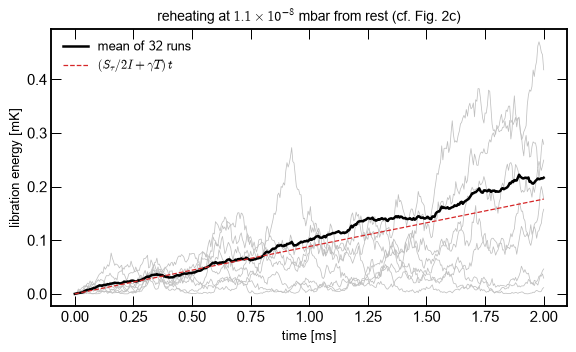

In [4]:
K_γ = trap.torque_stiffness_tensor[2, 2]
axis = np.array([0.0, 0.0, 1.0])  # the dumbbell's axis in the body frame


def libration_energy(sim):
    """Energy of the γ libration [K] from the tilt of the axis towards x and its rate"""
    n = sim.lab_directions(axis)
    ω = sim.angular_velocities_lab()
    θ = -n[:, 0]
    θ_dot = -np.cross(ω, n)[:, 0]
    return (0.5 * I_γ * θ_dot**2 + 0.5 * K_γ * θ**2) / kB


# levisim's stochastic Runge–Kutta scheme is weak order 2: on an undamped oscillator it loses energy
# at a rate that grows as (ΩΔt)³ (about 6 × 10³ s⁻¹ at 25 steps per libration period, 6 s⁻¹ at 250),
# so the step must resolve the 800 kHz libration finely
Δt = 5e-9
n_steps, n_runs, decimate = 400_000, 32, 1000
energies = []
for run in range(n_runs):
    sim = RigidBodySimulation(trap=trap, num_samples=n_steps, Δt=Δt, recoil=True, seed=1000 + run)
    energies.append(libration_energy(sim)[::decimate])
energies = np.array(energies)
t = sim.time_array[::decimate]
mean_E = energies.mean(axis=0)
slope, intercept = np.polyfit(t, mean_E, 1)
error = np.std(energies[:, -1]) / np.sqrt(n_runs) / t[-1]
print(f'simulated reheating ({n_runs} runs of {n_steps * Δt * 1e3:.0f} ms): {slope:.4f} ± {error:.4f} K/s; '
      f'predicted S/2I + γT = {Γ_sn + Γ_gas:.4f} K/s; backend {sim.backend_used}')

fig, ax = plt.subplots(figsize=(6.5, 4))
for row in energies[:8]:
    ax.plot(t * 1e3, row * 1e3, color='0.75', lw=0.6)
ax.plot(t * 1e3, mean_E * 1e3, 'k', lw=2, label=f'mean of {n_runs} runs')
ax.plot(t * 1e3, (Γ_sn + Γ_gas) * t * 1e3, 'C3--', label=r'$(S_\tau/2I + \gamma T)\,t$')
ax.set_xlabel('time [ms]')
ax.set_ylabel('libration energy [mK]')
ax.set_title(r'reheating at $1.1\times10^{-8}$ mbar from rest (cf. Fig. 2c)', fontsize=11)
ax.legend(frameon=False)
fig.tight_layout()

## 4. Parametric feedback cooling in the time domain

The tweezer power is modulated as $1 + \eta$, $\eta = G\,\theta\dot\theta$ (the measured libration angle
and its rate; the experiment uses a phase-locked loop at $2\Omega_l$), which stiffens the trap while the
angle grows. For a harmonic librator this removes energy at $G\Omega_l^2E^2/2K$, so against a heating
rate Γ the energy settles near $E_\mathrm{ss} \approx \sqrt{2K\Gamma/(G\Omega_l^2)}$. The cooling is run at
10⁻⁵ mbar, where the gas heating (γT ≈ 15 K/s) makes the settling take milliseconds instead of
seconds, with the gain chosen for $E_\mathrm{ss}$ = 0.24 K.

In levisim's point-dipole model the two librations (tilts of the axis towards $x$, γ, and towards the
beam axis $z$, α) are degenerate: the potential depends only on the angle between the axis and the
polarisation, so it is symmetric about $y$. Power modulation then conserves the angular momentum
$\ell_y$ of the conical motion of the axis, and the summed α and γ energy cannot fall below
$\Omega_l|\ell_y|$ for the two together (about half each); the paper notes the same coupling of the two orientational degrees of freedom
through the spin about the long axis (its Fig. 1(c) shoulders). Two starts are compared:
γ alone thermal at 300 K (α and the spin at rest, $\ell_y \approx 0$), and both librations and all
three angular velocities thermal at 300 K.

libration frequencies: Ωα/2π = 802.3 kHz, Ωγ/2π = 802.3 kHz
heating at 1e-5 mbar: 14.79 K/s; gain G = 1.396e-06 s
γ-only start: start 91 K; mean γ energy over the last 15 ms 0.494 K; Ω|ℓ_y| over the same time 0.894 K
full thermal start: start 45 K; mean γ energy over the last 15 ms 23.120 K; Ω|ℓ_y| over the same time 46.255 K


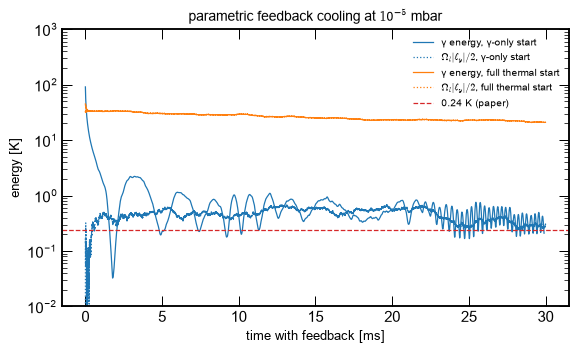

In [5]:
trap_cool = Trap(tweezer=tweezer, particle=dumbbell, gas=Gas(P=1e-5*mbar))
Γ_heat = (trap_cool.torque_noise_psd[2, 2] / (2 * I_γ) + trap_cool.Γrot_j['γ'] * 300.0 * kB)  # J/s
Ω_l = trap_cool.Ωθ['γ']
E_target = 0.24 * kB
gain = 2 * K_γ * Γ_heat / (Ω_l**2 * E_target**2)
print(f'libration frequencies: Ωα/2π = {trap_cool.Ωθ["α"] / (2 * π * 1e3):.1f} kHz, Ωγ/2π = {Ω_l / (2 * π * 1e3):.1f} kHz')
print(f'heating at 1e-5 mbar: {Γ_heat / kB:.2f} K/s; gain G = {gain:.3e} s')

K_lab = np.diag(trap_cool.torque_stiffness_tensor)
I_lab = np.array([trap_cool.Ij[j] for j in ('α', 'β', 'γ')])


def thermal_state(rng, all_modes):
    """Initial state: γ (and with all_modes, α and the three angular velocities) drawn at 300 K"""
    φ = np.array([0.0, 0.0, rng.normal() * np.sqrt(kB * 300 / K_lab[2])])
    ω0 = np.array([0.0, 0.0, rng.normal() * np.sqrt(kB * 300 / I_lab[2])])
    if all_modes:
        φ[0] = rng.normal() * np.sqrt(kB * 300 / K_lab[0])
        ω0 = rng.normal(size=3) * np.sqrt(kB * 300 / I_lab)
    q0 = quaternion_multiply(quaternion_from_rotation_vector(φ), dumbbell.orientation)
    R0 = quaternion_to_rotation_matrix(q0)
    return np.concatenate([np.zeros(6), q0, dumbbell.inertia_tensor @ (R0.T @ ω0)])


def conical_floor(sim):
    """Ω_l |ℓ_y| [K], ℓ_y the lab y angular momentum less the spin about the dumbbell axis"""
    n = sim.lab_directions(axis)
    L_lab = sim.angular_momenta_lab()
    spin = sim.X[:, 12]
    return Ω_l * np.abs(L_lab[:, 1] - spin * n[:, 1]) / kB


feedback = {'gain': gain, 'body_axis': axis, 'lab_axis': (1, 0, 0), 'max_modulation': 0.5}
segment_steps, decimate_cool, n_segments = 400_000, 50, 15
cooling = {}
for all_modes in (False, True):
    X0 = thermal_state(np.random.default_rng(5), all_modes)
    E, floor = [], []
    for segment in range(n_segments):
        sim = RigidBodySimulation(trap=trap_cool, num_samples=segment_steps, Δt=Δt, recoil=True,
                                  seed=50 + segment, X0=X0, parametric_feedback=feedback)
        E.append(libration_energy(sim)[:-1:decimate_cool])
        floor.append(conical_floor(sim)[:-1:decimate_cool])
        X0 = sim.X[-1].copy()
    cooling[all_modes] = (np.concatenate(E), np.concatenate(floor))
t_cool = np.arange(len(cooling[False][0])) * Δt * decimate_cool
window = 400  # 0.1 ms
late = slice(len(t_cool) // 2, None)
for all_modes, label in ((False, 'γ-only start'), (True, 'full thermal start')):
    E, floor = cooling[all_modes]
    print(f'{label}: start {E[:window].mean():.0f} K; mean γ energy over the last {t_cool[-1] * 1e3 / 2:.0f} ms '
          f'{E[late].mean():.3f} K; Ω|ℓ_y| over the same time {floor[late].mean():.3f} K')

fig, ax = plt.subplots(figsize=(6.5, 4))
for (all_modes, label), colour in zip(((False, 'γ-only start'), (True, 'full thermal start')), ('C0', 'C1')):
    E, floor = cooling[all_modes]
    E_smooth = np.convolve(E, np.ones(window) / window, mode='valid')
    ax.semilogy(t_cool[:len(E_smooth)] * 1e3, E_smooth, color=colour, label=f'γ energy, {label}')
    ax.semilogy(t_cool * 1e3, floor / 2, color=colour, ls=':', lw=1, label=r'$\Omega_l|\ell_y|/2$, ' + label)
ax.axhline(0.24, color='C3', ls='--', label='0.24 K (paper)')
ax.set_xlabel('time with feedback [ms]')
ax.set_ylabel('energy [K]')
ax.set_ylim(1e-2, 1e3)
ax.set_title(r'parametric feedback cooling at $10^{-5}$ mbar', fontsize=11)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

From the γ-only start (drawn at 300 K; 91 K in this run) the feedback cools the librator to about half a kelvin
within milliseconds, near the 0.24 K for which the gain was chosen; the excess follows the conical
angular momentum that the gas and recoil noise build up meanwhile (dotted line). The steady value is
set by the gain against the heating, so agreement with 0.24 K follows from the choice of gain rather
than being a prediction (the paper's floor is set by its detection and loop, which are not modelled). From the full thermal start the
γ energy stalls near $\Omega_l|\ell_y|/2$, its share of the bound: the conical angular momentum of the degenerate pair is out of
reach of a symmetric stiffness modulation and is only exchanged with the gas and the recoil noise.
The experiment does reach 0.24 K, which suggests that its α and γ are not exactly degenerate (the
finite size of the dumbbell in the focal field and the tight focus break the symmetry about the
polarisation); levisim's point-dipole torque does not include these corrections.

## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| torque shot-noise heating with the paper's parameters (Eq. (3)) | 0.31 K/s | 0.311 K/s, identical to Eq. (3) to round-off | agree |
| measured residual heating at 1.1 × 10⁻⁸ mbar | 0.50(6) K/s | 0.31 K/s (paper's particle parameters); 0.09 K/s for levisim's nominal 2 × 136 nm coupled-dipole dumbbell (0.07 recoil + 0.02 gas) | same gap as the paper's own prediction (0.31 against 0.50); levisim's nominal particle is less anisotropic and heavier |
| libration frequency | 757 kHz | 802 kHz (nominal dumbbell, paraxial 712 nm waist) | 6 % high |
| time-domain reheating | linear (Fig. 2c) | ensemble slope equals S/2I + γT within the statistics (see the printout); needs ≳ 250 steps per libration period | consistency check |
| parametric feedback cooling | 0.24(3) K | γ-only start: 0.49 K at 10⁻⁵ mbar, gain set for 0.24 K, floor rising with the conical angular momentum ℓ_y; full thermal start: γ stalls at 23 K, half of Ω_l\|ℓ_y\| = 46 K | mechanism reproduced for one mode; degenerate α/γ in the point-dipole model limit single-channel parametric cooling (open question) |

Not reproduced: the pressure dependence of Fig. 3 below 10⁻⁷ mbar in detail (it needs the measured I,
Δα and scattered power), the laser-noise test of Fig. 4 (levisim has no intensity-noise element yet),
and the shoulders of the room-temperature spectrum (Fig. 1c), which come from the coupling of the
librations to the thermal spin about the long axis, present in `RigidBodySimulation` but not analysed here.

In [6]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 70.8 s
